In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

**1. Coletar dados do dataset a. breast_cancer.csv b. https://leandrolessa.com.br/wp-content/uploads/2024/07/breast_cance r.zip**

In [9]:
df = pd.read_csv('./dataset/breast_cancer.csv')
df.head(10)

,Age,BMI,Glucose,Insulin,HOMA,Leptin,Adiponectin,Resistin,MCP.1,Classification
0,48,23.500000,70,2.707,0.467409,8.8071,9.702400,7.99585,417.114,1
1,83,20.690495,92,3.115,0.706897,8.8438,5.429285,4.06405,468.786,1
2,82,23.124670,91,4.498,1.009651,17.9393,22.432040,9.27715,554.697,1
3,68,21.367521,77,3.226,0.612725,9.8827,7.169560,12.76600,928.220,1
4,86,21.111111,92,3.549,0.805386,6.6994,4.819240,10.57635,773.920,1
5,49,22.854458,92,3.226,0.732087,6.8317,13.679750,10.31760,530.410,1
6,89,22.700000,77,4.690,0.890787,6.9640,5.589865,12.93610,1256.083,1
7,76,23.800000,118,6.470,1.883201,4.3110,13.251320,5.10420,280.694,1
8,73,22.000000,97,3.350,0.801543,4.4700,10.358725,6.28445,136.855,1
9,75,23.000000,83,4.952,1.013839,17.1270,11.578990,7.09130,318.302,1


**2. Analisar os dados coletados**

In [11]:
#Descobrindo tamanho do dataset
df.shape
print("Linhas:", df.shape[0])
print("Colunas:", df.shape[1])

Linhas: 175
Colunas: 10


In [12]:
#Conhecendo as colunas do dataset
df.columns

Index(['Age', 'BMI', 'Glucose', 'Insulin', 'HOMA', 'Leptin', 'Adiponectin',
       'Resistin', 'MCP.1', 'Classification'],
      dtype='str')

In [13]:
#Ver os tipos dos dados
df.dtypes

Age                 int64
BMI               float64
Glucose             int64
Insulin           float64
HOMA              float64
Leptin            float64
Adiponectin       float64
Resistin          float64
MCP.1             float64
Classification      int64
dtype: object

In [14]:
#Analisando o dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             175 non-null    int64  
 1   BMI             175 non-null    float64
 2   Glucose         175 non-null    int64  
 3   Insulin         175 non-null    float64
 4   HOMA            175 non-null    float64
 5   Leptin          175 non-null    float64
 6   Adiponectin     175 non-null    float64
 7   Resistin        175 non-null    float64
 8   MCP.1           175 non-null    float64
 9   Classification  175 non-null    int64  
dtypes: float64(7), int64(3)
memory usage: 13.8 KB


In [22]:
#Estatísticas dos dados
df.describe()

,Age,BMI,Glucose,Insulin,HOMA,Leptin,Adiponectin,Resistin,MCP.1,Classification
count,175.00000,175.000000,175.000000,175.000000,175.000000,175.000000,175.000000,175.000000,175.000000,175.000000
mean,57.48000,27.530602,100.828571,10.896189,3.038455,27.011812,10.039447,15.479018,547.081206,1.702857
std,15.19938,4.846336,24.492417,11.049329,4.063781,19.244423,6.579671,12.616243,363.585057,0.458311
min,24.00000,18.370000,60.000000,2.432000,0.467409,4.311000,1.656020,3.210000,45.843000,1.000000
25%,45.00000,23.005000,87.000000,4.364000,0.986620,12.450000,5.470395,7.005650,269.814500,1.000000
50%,55.00000,27.688778,95.000000,6.200000,1.449709,20.450000,8.404430,11.730000,468.786000,2.000000
75%,69.00000,31.224446,104.000000,12.426500,3.071407,37.843000,11.900000,19.705055,723.518000,2.000000
max,89.00000,38.578759,201.000000,58.460000,25.050342,90.280000,38.040000,82.100000,1698.440000,2.000000


In [ ]:
#Verificar valores nulos
df.isnull().sum()

Age               0
BMI               0
Glucose           0
Insulin           0
HOMA              0
Leptin            0
Adiponectin       0
Resistin          0
MCP.1             0
Classification    0
dtype: int64

In [17]:
#Verificar valores duplicados
df.duplicated().sum()

np.int64(59)

In [26]:
# verifica todas as ocorrências duplicadas.
df[df.duplicated(keep=False)]

,Age,BMI,Glucose,Insulin,HOMA,Leptin,Adiponectin,Resistin,MCP.1,Classification
57,68,21.082813,102,6.200,1.559920,9.6994,8.574655,13.74244,448.799,2
58,51,19.132653,93,4.364,1.001102,11.0816,5.807620,5.57055,90.600,2
59,62,22.656250,92,3.482,0.790182,9.8648,11.236235,10.69548,703.973,2
60,38,22.499637,95,5.261,1.232828,8.4380,4.771920,15.73606,199.055,2
61,69,21.513859,112,6.683,1.846290,32.5800,4.138025,15.69876,713.239,2
...,...,...,...,...,...,...,...,...,...,...
170,45,26.850000,92,3.330,0.755688,54.6800,12.100000,10.96000,268.230,2
171,62,26.840000,100,4.530,1.117400,12.4500,21.420000,7.32000,330.160,2
172,65,32.050000,97,5.730,1.370998,61.4800,22.540000,10.33000,314.050,2
173,72,25.590000,82,2.820,0.570392,24.9600,33.750000,3.27000,392.460,2


In [27]:
# marca todas as ocorrências pertencentes a grupos duplicados.
df.duplicated(keep=False)

0      False
1      False
2      False
3      False
4      False
       ...  
170     True
171     True
172     True
173     True
174     True
Length: 175, dtype: bool

**3. Tratar os dados coletados**

In [29]:
#Como descobrimos que existem 59 duplicados, podemos removê-los.
print("Antes:", df.shape)

df = df.drop_duplicates()
print("Depois:", df.shape)

Antes: (175, 10)
Depois: (116, 10)


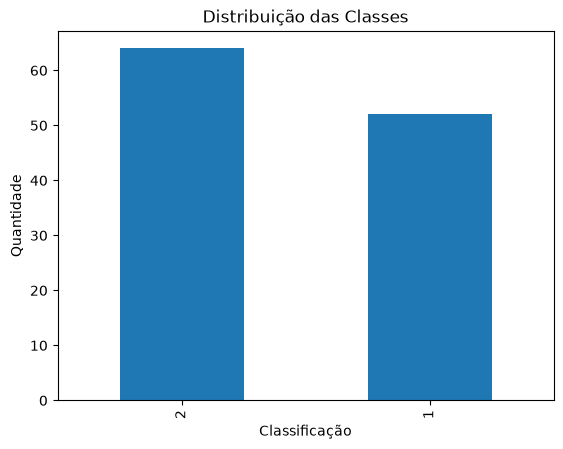

In [35]:
#Visualizando a quantidade de cada classe

df["Classification"].value_counts().plot(kind="bar")

plt.xlabel("Classificação")
plt.ylabel("Quantidade")
plt.title("Distribuição das Classes")

plt.show()

In [36]:
saudaveis = df[df["Classification"] == 1]
saudaveis["Age"].mean()

np.float64(58.07692307692308)

In [40]:
#Média de glicose dos pacientes doentes

#Criamos o grupo de doentes
doentes = df[df["Classification"] == 2]

#E calculamos:
doentes["Glucose"].mean()

#Comparando várias médias
df.groupby("Classification")[["Age", "BMI", "Glucose", "Insulin"]].mean()

,Age,BMI,Glucose,Insulin
Classification,,,,
1,58.076923,28.317336,88.230769,6.933769
2,56.671875,26.984740,105.562500,12.513219


In [45]:
#Correlação: mede o quanto duas variáveis estão relacionadas.
df.corr(numeric_only=True)

#Quanto mais próximo de 1 mais as duas variaveis se relacionam positivamente, quanto mais próximo de -1 mais se relacionam negativamente e quanto mais próximo de 0 menos se relacionam.

,Age,BMI,Glucose,Insulin,HOMA,Leptin,Adiponectin,Resistin,MCP.1,Classification
Age,1.000000,0.008530,0.230106,0.032495,0.127033,0.102626,-0.219813,0.002742,0.013462,-0.043555
BMI,0.008530,1.000000,0.138845,0.145295,0.114480,0.569593,-0.302735,0.195350,0.224038,-0.132586
Glucose,0.230106,0.138845,1.000000,0.504653,0.696212,0.305080,-0.122121,0.291327,0.264879,0.384315
Insulin,0.032495,0.145295,0.504653,1.000000,0.932198,0.301462,-0.031296,0.146731,0.174356,0.276804
HOMA,0.127033,0.114480,0.696212,0.932198,1.000000,0.327210,-0.056337,0.231101,0.259529,0.284012
Leptin,0.102626,0.569593,0.305080,0.301462,0.327210,1.000000,-0.095389,0.256234,0.014009,-0.001078
Adiponectin,-0.219813,-0.302735,-0.122121,-0.031296,-0.056337,-0.095389,1.000000,-0.252363,-0.200694,-0.019490
Resistin,0.002742,0.195350,0.291327,0.146731,0.231101,0.256234,-0.252363,1.000000,0.366474,0.227310
MCP.1,0.013462,0.224038,0.264879,0.174356,0.259529,0.014009,-0.200694,0.366474,1.000000,0.091381
Classification,-0.043555,-0.132586,0.384315,0.276804,0.284012,-0.001078,-0.019490,0.227310,0.091381,1.000000


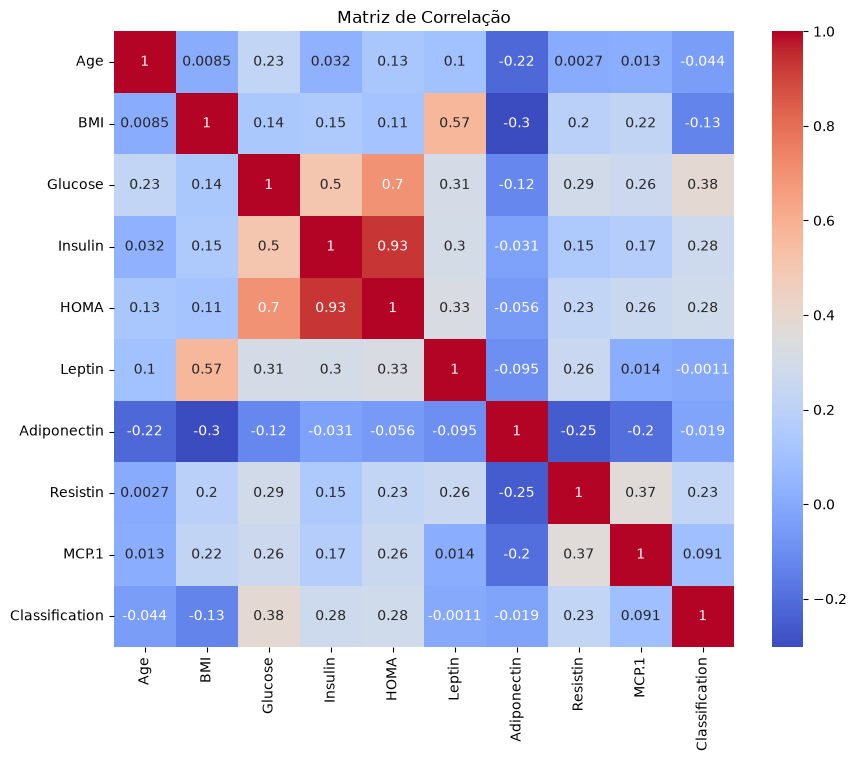

In [48]:
#visualisar c Seaborn
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.title("Matriz de Correlação")
plt.show()

In [50]:
#Encontrando a correlação com Classification
df.corr(numeric_only=True)["Classification"]

Age              -0.043555
BMI              -0.132586
Glucose           0.384315
Insulin           0.276804
HOMA              0.284012
Leptin           -0.001078
Adiponectin      -0.019490
Resistin          0.227310
MCP.1             0.091381
Classification    1.000000
Name: Classification, dtype: float64

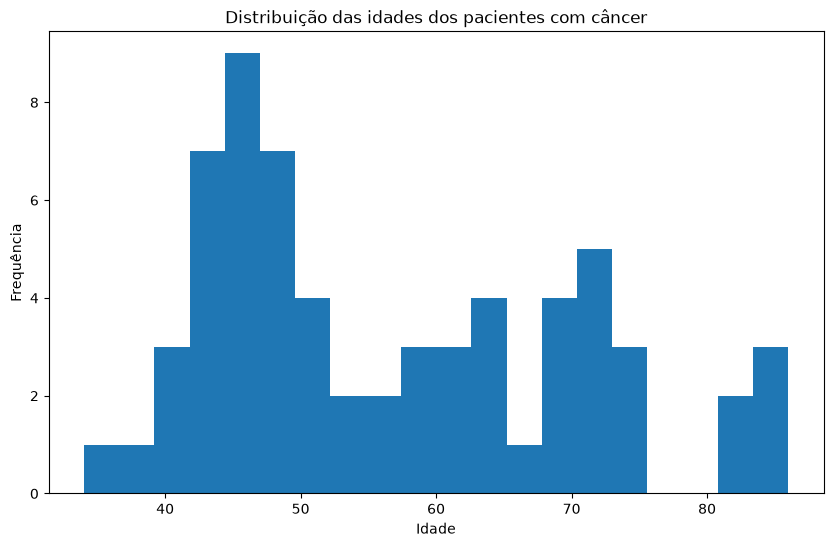

In [52]:
doentes = df[df["Classification"] == 2]
plt.figure(figsize=(10, 6))

plt.hist(doentes["Age"], bins=20)

plt.xlabel("Idade")
plt.ylabel("Frequência")
plt.title("Distribuição das idades dos pacientes com câncer")

plt.show()

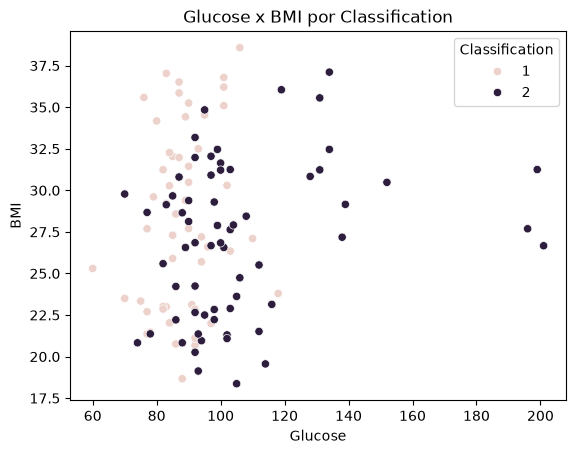

In [53]:
#Gráfico de dispersão
sns.scatterplot(
    data=df,
    x="Glucose",
    y="BMI",
    hue="Classification"
)

plt.title("Glucose x BMI por Classification")
plt.show()

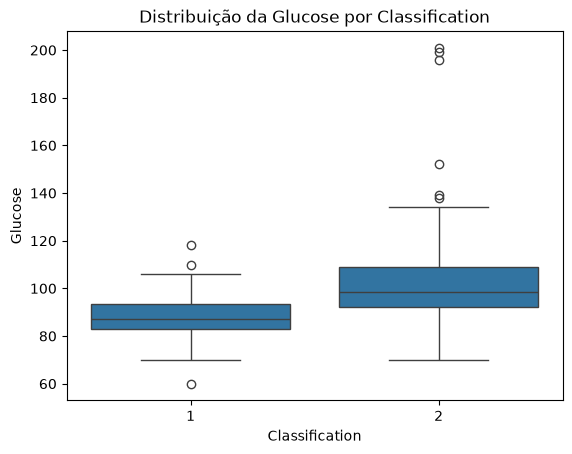

In [54]:
#Boxplot para visualizar a distribuição de Glucose por Classification
sns.boxplot(
    data=df,
    x="Classification",
    y="Glucose"
)

plt.title("Distribuição da Glucose por Classification")
plt.show()

**5. Criar algoritmo de Random Forest 6. Responder às questões práticas do desafio** 

In [59]:
#Random forest
X = df.drop("Classification", axis=1)
y = df["Classification"]

#Separando treinamento e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

#Criando o Random Forest
modelo = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

#Treinamos
modelo.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [63]:
#Fazendo previsões
y_pred = modelo.predict(X_test)
y_pred

array([2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       2, 1])

In [62]:
y_test

83     2
4      1
42     1
40     1
10     1
47     1
110    2
36     1
70     2
11     1
45     1
26     1
94     2
53     2
18     1
0      1
56     2
85     2
109    2
100    2
93     2
88     2
67     2
12     1
Name: Classification, dtype: int64

In [64]:
#Avaliando o modelo
modelo.score(X_test, y_test)

0.7916666666666666

In [ ]:
#Importância das features
import pandas as pd

importancias = pd.Series(
    modelo.feature_importances_,
    index=X.columns
)

importancias.sort_values(ascending=False)

Glucose        0.196806
Age            0.152060
BMI            0.126804
Resistin       0.099197
Insulin        0.091571
Adiponectin    0.087204
Leptin         0.087126
HOMA           0.083327
MCP.1          0.075904
dtype: float64

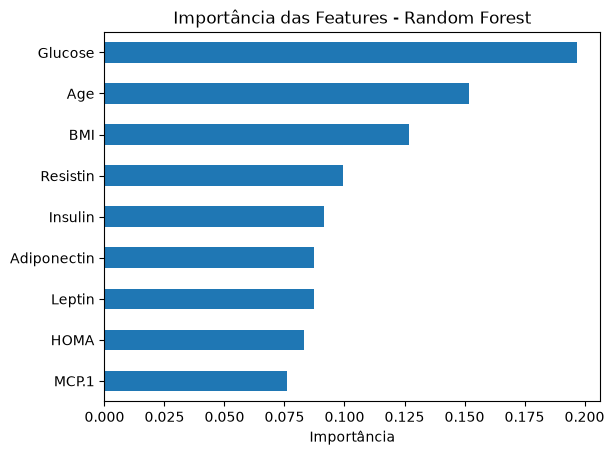

In [ ]:
#Visualizando a importância das features
importancias.sort_values().plot(kind="barh")

plt.xlabel("Importância")
plt.title("Importância das Features - Random Forest")
plt.show()

In [ ]:
#Matriz de confusão
matriz = confusion_matrix(y_test, y_pred)

print(matriz)

[[ 9  3]
 [ 2 10]]
